# Multiple Linear Regression | Route AI & ML Diploma

The goal of this project is to predict median house values using California housing data. This is a supervised regression problem because the target is a continuous numerical value.

Dataset: California Housing Dataset (Kaggle).
The dataset contains 20,640 observations and 10 original columns, describing California census block groups rather than individual houses.

This notebook follows the workflow practiced during our Route session, with explanatory notes added for readability. Course guidance: Aya Hossam.

To run locally, place housing.csv beside the notebook. On Kaggle, attach the linked dataset and update the CSV path in the loading cell. The saved outputs below are from the original course run.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Load and inspect the data

In [2]:
df = pd.read_csv('housing.csv')
print('Data is read successfuly!')

Data is read successfuly!


In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
print("Shape:", df.shape)

Shape: (20640, 10)


In [6]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [7]:
df['ocean_proximity'].unique()

<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

In [8]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [9]:
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


### Feature distributions

Histograms help identify skewness, unusual distributions and differences in scale. Housing values and housing median age also show upper limits in this dataset.

In [ ]:
# Matplotlib Visualization

df.hist(bins=50, figsize=(20, 15))
plt.show() 

### Missing values and duplicates

In [ ]:
df.isna().sum().rename("Missing values")

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

## 3. Income categories for stratified sampling

Median income is an important predictor. We group it into five bands to maintain similar income proportions in the training and testing sets. The temporary category is used for splitting, not as a model feature.

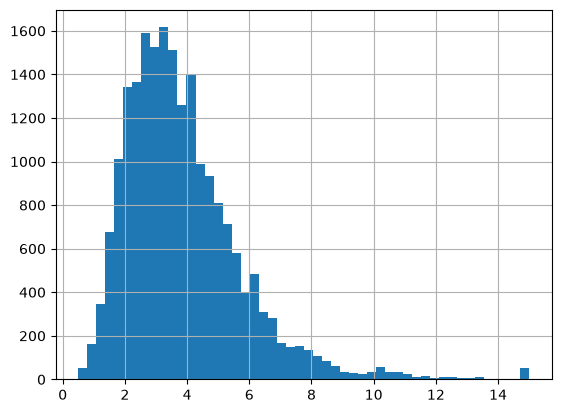

In [11]:
df['median_income'].hist(bins=50)
plt.show()

In [12]:
df["income_cat"] = pd.cut(df["median_income"],
bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
labels=[1, 2, 3, 4, 5])

In [13]:
df[['income_cat','median_income']].head()

,income_cat,median_income
0,5,8.3252
1,5,8.3014
2,5,7.2574
3,4,5.6431
4,3,3.8462


In [14]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'income_cat'],
      dtype='str')

In [15]:
df['income_cat'].value_counts()

income_cat
3    7236
2    6581
4    3639
5    2362
1     822
Name: count, dtype: int64

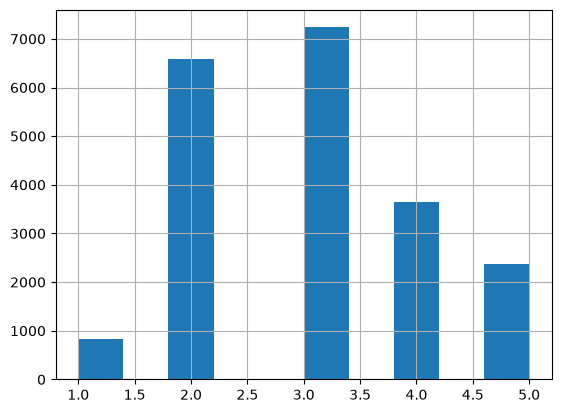

In [16]:
df['income_cat'].hist()
plt.show()

##  4. Exploratory data analysis
Geographic scatter plots reveal how house values vary across California. In the colored map, larger markers represent higher population and the color represents median house value.
* Visualizing the data 

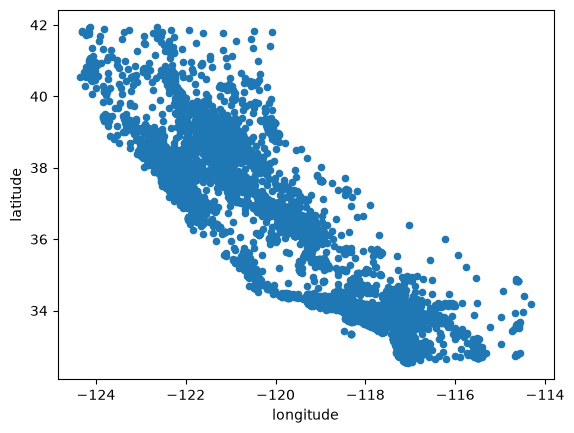

In [18]:
df.plot(kind="scatter", x="longitude", y="latitude")
plt.show()


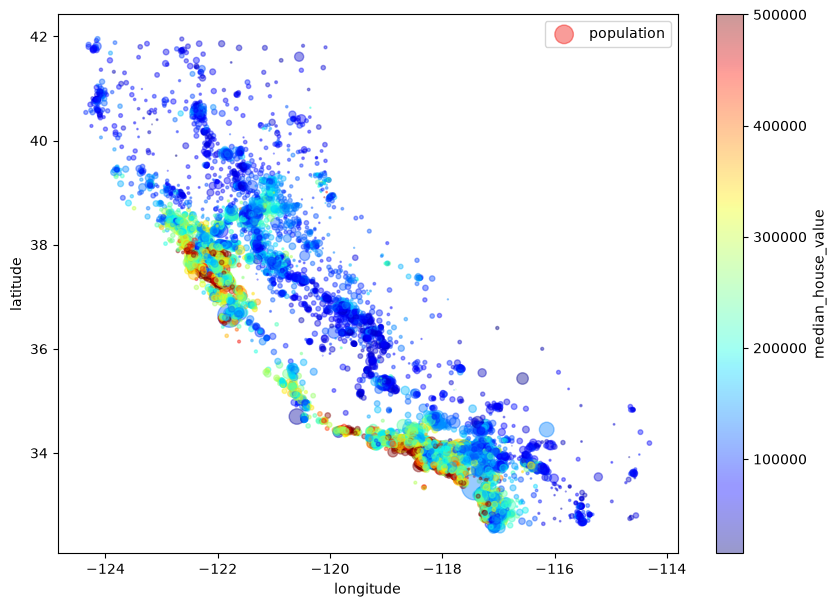

In [19]:
df.plot(kind="scatter", x="longitude", y="latitude", alpha=0.4,
            s=df["population"] / 100, label="population", figsize=(10, 7),
            c="median_house_value", cmap=plt.get_cmap("jet"), colorbar=True,sharex=False)
plt.show()

### Correlation analysis

The correlation matrix measures linear relationships between numerical features. In this course run, median income has the strongest positive correlation with median house value (about 0.688). Correlation does not establish causation.

The heatmap and scatter matrix help visualize these relationships from different perspectives.

In [20]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


In [21]:
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

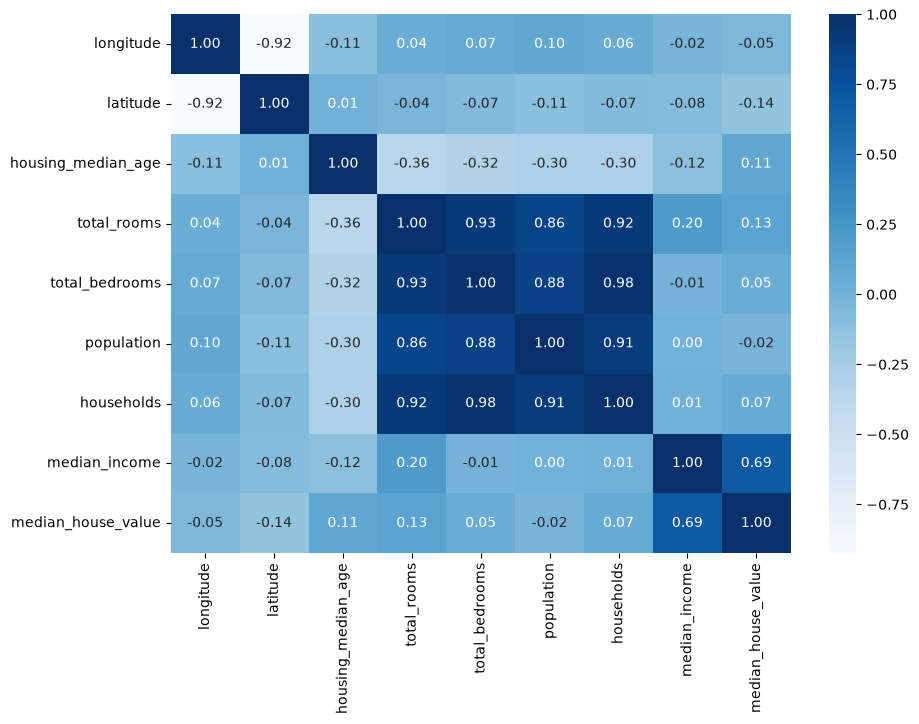

In [22]:
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues')
plt.show()

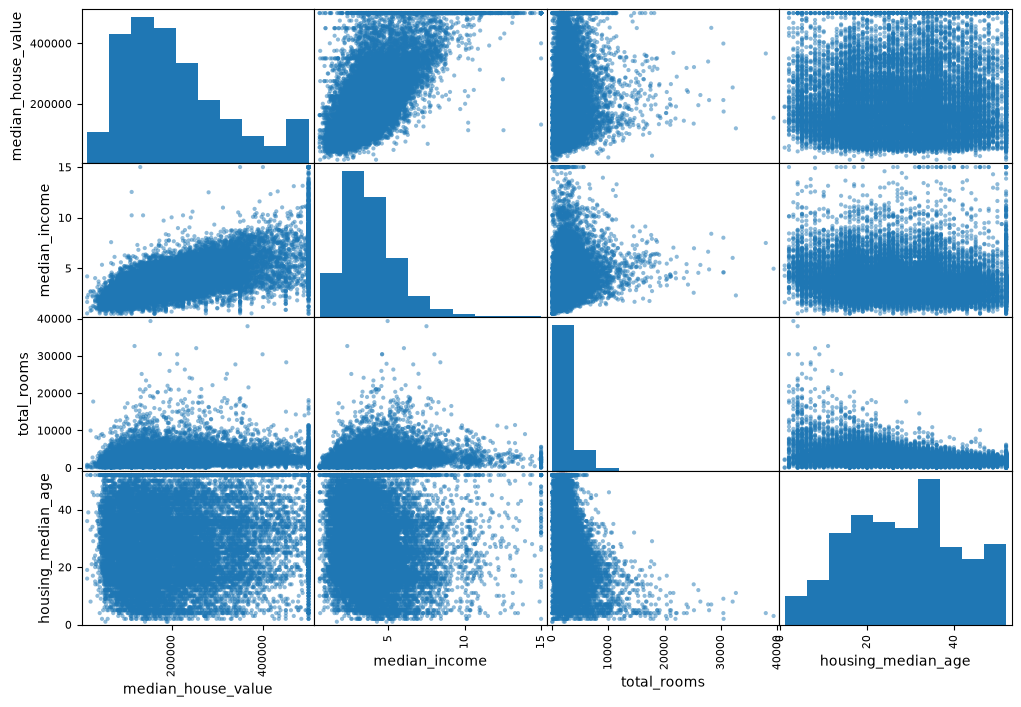

In [23]:
attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
scatter_matrix(df[attributes], figsize=(12, 8))
plt.show()

## 5. Feature engineering

Raw totals may depend on the size of each district. Three ratios provide additional context:
- rooms_per_household: total rooms divided by households.
- bedrooms_per_room: total bedrooms divided by total rooms.
- population_per_household: population divided by households.
We then compare these features with the target through correlation analysis.

In [24]:
df["rooms_per_household"]      = df["total_rooms"] / df["households"]
df["bedrooms_per_room"]        = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

In [25]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value          1.000000
median_income               0.688075
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
households                  0.065843
total_bedrooms              0.049686
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64

## 6.Encoding: 

One-hot encoding converts ocean proximity into binary columns without introducing an artificial order. Dropping the first category avoids redundant dummy columns when the model includes an intercept.

In this classroom workflow, the encoder is fitted before splitting. For a stricter evaluation in a future version, fit the encoder on training data only and apply the learned encoding to the test set.

In [26]:
cat_encoder = OneHotEncoder(drop="first", sparse_output=False).set_output(transform="pandas")

housing_cat_encoded = cat_encoder.fit_transform(df[["ocean_proximity"]])

print(cat_encoder.categories_)

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [27]:
encoded_df=pd.DataFrame(housing_cat_encoded,
                        columns=cat_encoder.get_feature_names_out(['ocean_proximity']),
                        index=df.index)
df=pd.concat([df.drop(columns="ocean_proximity"), encoded_df],axis=1)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,income_cat,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,5,6.984127,0.146591,2.555556,0.0,0.0,1.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,5,6.238137,0.155797,2.109842,0.0,0.0,1.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,5,8.288136,0.129516,2.802260,0.0,0.0,1.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,4,5.817352,0.184458,2.547945,0.0,0.0,1.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,3,6.281853,0.172096,2.181467,0.0,0.0,1.0,0.0


In [29]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,income_cat,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,2,5.045455,0.224625,2.560606,1.0,0.0,0.0,0.0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,2,6.114035,0.215208,3.122807,1.0,0.0,0.0,0.0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,2,5.205543,0.215173,2.325635,1.0,0.0,0.0,0.0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,2,5.329513,0.219892,2.123209,1.0,0.0,0.0,0.0
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,2,5.254717,0.221185,2.616981,1.0,0.0,0.0,0.0


## 7. Train/test split

We separate predictors (x) from the target (y) and reserve 20% of the data for evaluation. Stratification on income categories preserves income proportions, while a fixed random state makes the split reproducible.

In [30]:
x = df.drop(['median_house_value','income_cat'],axis=1)
y = df["median_house_value"]

In [31]:
x_train,x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state=42, stratify=df['income_cat'] )

## 8. Missing-value imputation
Median imputation replaces missing numerical values with the training-set median, which is less sensitive to extreme values than the mean. The same fitted imputer transforms the test set.

In [32]:
imputer = SimpleImputer(strategy="median")

x_train = imputer.fit_transform(x_train)   # learn medians from train
x_test  = imputer.transform(x_test)        # reuse the same medians

imputer.statistics_

array([-1.18510000e+02,  3.42600000e+01,  2.90000000e+01,  2.12500000e+03,
        4.34000000e+02,  1.16700000e+03,  4.08000000e+02,  3.53850000e+00,
        5.23557310e+00,  2.03105786e-01,  2.82231619e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00])

## 9. Feature scaling
StandardScaler uses the training mean and standard deviation to standardize features. The same transformation is applied to the test set.

Course implementation note: The following model uses the lowercase imputed arrays x_train and x_test, rather than the uppercase scaled arrays. Ordinary least squares does not require scaling for predictions in the usual full-rank setting; scaling is demonstrated separately here.

In [33]:
scaler = StandardScaler()

X_train = scaler.fit_transform(x_train)   
X_test  = scaler.transform(x_test)   

## 10. Model training
Multiple linear regression estimates a continuous target from several predictors:


The coefficients and intercept are learned by minimizing squared residuals. Our theory session also explored gradient descent and learning rates; the scikit-learn estimator here solves ordinary least squares directly.

In [34]:
lin_reg = LinearRegression()
lin_reg.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[-27979.46,-26560.76, 1068.54,...,227055.53, -4307.45, 3301.93]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.457e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](15,)","[314929.64, 65343.09, 22049.02,..., 29.18, 4.49, 1.41]"


## 11. Model evaluation
We evaluate predictions using three regression metrics:
Metric	Interpretation
RMSE	Typical error magnitude with greater weight on larger errors, in dollars.
MAE	Average absolute prediction error, in dollars.
R²	Proportion of target variation explained relative to a mean-prediction reference; not classification accuracy.


We also compare training and testing R² to observe the generalization gap.

In [35]:
y_pred=lin_reg.predict(x_test)

lin_mse = mean_squared_error(y_test, y_pred)
lin_rmse = np.sqrt(lin_mse)

print(lin_rmse)


72013.32213353629


In [36]:
lin_mae  = mean_absolute_error(y_test, y_pred)
lin_mae


50010.550275888265

In [37]:
lin_r2   = r2_score(y_test, y_pred)
lin_r2

0.6125852950030206

**Compare train vs test** to detect overfitting / underfitting:

In [38]:
y_pred_train = lin_reg.predict(x_train)
print(f"Train R2: {r2_score(y_train, y_pred_train):.3f} | Test R2: {lin_r2:.3f}")

Train R2: 0.660 | Test R2: 0.613


## 12. Results and conclusion

Metric	Original course result:

    Training R²	0.660

    Testing R²	0.613
    
    Test MAE	$50,010.55
    
    Test RMSE	$72,013.32


The model explains approximately 61.3% of the variation in the held-out target relative to its mean. The prediction errors remain substantial, and the training score is slightly higher than the test score. This difference alone does not establish overfitting.

This exercise connects data exploration, feature engineering, preprocessing and multiple linear regression into a complete introductory ML workflow.

Limitations and potential improvements: The dataset contains historical area-level values and capped house values. The instructor's extended notebook also explores removing capped targets, cross-validation and prediction plots. Those are useful follow-up experiments, but removing capped targets changes the population being evaluated, so its scores should not be compared directly with the results above. For a stricter future experiment, perform model-development EDA and fit all learned preprocessing using training data only.

Acknowledgments: This is an instructor-guided project from Route's AI & ML Diploma. 
the Markdown was expanded to explain the steps more clearly.
